# Swiss Dwellings — Tabular Autoencoder for Noise Anomaly Detection & Quiet Twin Search

**Dataset:** [Swiss Dwellings v3.0.0](https://zenodo.org/records/7788422) (Archilyse AG, CC BY 4.0)  
**Goal (Monday — `01_autoencoder/`):**
1. Load `simulations.csv` and aggregate room-level environmental & geometric simulations to the **apartment level** (`24 features` across Acoustics, Daylight, Viewshed, and Layout/Centrality).
2. Split the data by `building_id` **before** scaling (train on normal/quiet apartments only; hold out noisy anomalies for evaluation).
3. Train and compare **three autoencoder setups** (`DenseAE` latent=4, `DenseAE` latent=8, and `Conv1DAE` latent=8) on the same split and seed.
4. Demonstrate **Anomaly Detection** (flagging apartments with severe/unusual acoustic exposure) and **Quiet Twin Similarity Search** in latent space.
5. Export the trained autoencoder to **ONNX** (`../model_app/anomaly_ae.onnx`) and verify parity with PyTorch.

### Block 1: Imports, Reproducibility, Relative Paths & Dataset Staging
This block:
- Imports `numpy`, `pandas`, `matplotlib`, `scikit-learn`, and `PyTorch`.
- Sets up **relative paths** from `01_autoencoder/notebook/` (`../data`, `../figures`, `../model_app`, `../models` when run from `notebook/`) as required by the submission guidelines.
- Fixes `RANDOM_STATE = 42` across NumPy and PyTorch so all experiments are 100% reproducible.
- Checks whether `simulations.csv` (`1.52 GB`) is already in `../data/simulations.csv`; if not, it automatically extracts or copies it from `~/Downloads` only if it is missing from `01_autoencoder/data/`.

In [1]:
%pip install matplotlib numpy pandas scikit-learn torch onnx onnxscript onnxruntime

  Using cached numpy-2.5.5-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
  Using cached coloredlogs-15.0.1-py2.py3-none-any.whl.metadata (12 kB)
  Using cached humanfriendly-10.0-py2.py3-none-any.whl.metadata (9.2 kB)
  Using cached pyreadline3-3.5.6-py3-none-any.whl.metadata (4.7 kB)
Using cached numpy-2.5.5-cp312-cp312-win_amd64.whl (12.6 MB)

  Attempting uninstall: numpy

    Found existing installation: numpy 1.26.4

   ---------- ----------------------------- 1/4 [numpy]
    Uninstalling numpy-1.26.4:
   ---------- ----------------------------- 1/4 [numpy]
   ---------- ----------------------------- 1/4 [numpy]
   ---------- ----------------------------- 1/4 [numpy]
   ---------- ----------------------------- 1/4 [numpy]
      Successfully uninstalled numpy-1.26.4
   ---------- ----------------------------- 1/4 [numpy]
   ---------- ----------------------------- 1/4 [numpy]
   ---------- ----------------------------- 1/4 [numpy]
   ---------- ----------------------------- 1/4 [nump

In [2]:
import json
import shutil
import time
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

# Relative paths work from the repository root, 01_autoencoder/, or notebook/.
DAY_DIR = next(
    (candidate for candidate in [Path("01_autoencoder"), Path("."), Path("..")]
     if (candidate / "notebook" / "autoencoder.ipynb").is_file()),
    None,
)
if DAY_DIR is None:
    raise FileNotFoundError("Run this notebook from the repository, 01_autoencoder/, or notebook/ folder.")
DATA_DIR = DAY_DIR / "data"
FIG_DIR = DAY_DIR / "figures"
MODEL_APP_DIR = DAY_DIR / "model_app"
MODELS_HF_DIR = DAY_DIR / "models"

for d in [DATA_DIR, FIG_DIR, MODEL_APP_DIR / "examples", MODELS_HF_DIR]:
    d.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

def save_fig(name: str):
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=160, bbox_inches="tight")
    shutil.copy2(path, MODELS_HF_DIR / f"{name}.png")
    print(f"Saved figure -> {path}")

def locate_or_stage_simulations_csv(data_dir: Path) -> Path:
    target_csv = data_dir / "simulations.csv"
    if target_csv.exists():
        print(f"Found simulations.csv at: {target_csv.resolve()} ({target_csv.stat().st_size / (1024**2):.1f} MB)")
        return target_csv

    existing_in_data = list(data_dir.rglob("simulations.csv"))
    if existing_in_data:
        print(f"Found simulations.csv at: {existing_in_data[0].resolve()}")
        return existing_in_data[0]

    downloads = Path.home() / "Downloads"
    print(f"simulations.csv not in {data_dir.resolve()} yet. Searching {downloads}...")
    csv_matches = list(downloads.glob("**/simulations.csv"))
    if csv_matches:
        src = csv_matches[0]
        shutil.copy2(src, target_csv)
        return target_csv

    zip_matches = list(downloads.glob("*swiss*dwellings*.zip")) + list(downloads.glob("*7788422*.zip"))
    if zip_matches:
        zip_path = zip_matches[0]
        with zipfile.ZipFile(zip_path, "r") as zf:
            member = [m for m in zf.namelist() if m.endswith("simulations.csv")][0]
            with zf.open(member) as src_f, open(target_csv, "wb") as dst_f:
                shutil.copyfileobj(src_f, dst_f)
        return target_csv

    raise FileNotFoundError("Could not find simulations.csv in data/ or ~/Downloads.")

SIMULATIONS_CSV = locate_or_stage_simulations_csv(DATA_DIR)

Using device: cpu
Found simulations.csv at: D:\MaAI IAAC\Term 1\AI Methods\Hackathon 16-20.11.2026\hackathon_team5_swiss_dwellings\data\simulations.csv (1521.0 MB)


## 1. Inspect `simulations.csv` & Aggregate Room Rows to Apartments

### Block 2: Schema Inspection (Header Read)
`simulations.csv` contains **375 columns** per room (`8` identifier/usage columns + `367` simulation columns).  
This block reads only the header row (`nrows=0`) to quickly inspect the column prefixes (`view_`, `sun_`, `connectivity_`, `layout_`, `window_noise_`, `noise_`) without loading the entire 1.52 GB file into RAM.

In [3]:
# Preview header column categories
header_cols = pd.read_csv(SIMULATIONS_CSV, nrows=0).columns.tolist()
print(f"Total columns in simulations.csv: {len(header_cols)}")
prefixes = Counter(c.split("_")[0] for c in header_cols)
for prefix, count in prefixes.most_common(12):
    examples = [c for c in header_cols if c.startswith(prefix + "_") or c == prefix][:3]
    print(f"  {prefix:15s}: {count:3d} cols  (e.g. {', '.join(examples)})")

Total columns in simulations.csv: 369
  sun            : 126 cols  (e.g. sun_201803210800_max, sun_201803210800_mean, sun_201803210800_median)
  view           : 126 cols  (e.g. view_buildings_max, view_buildings_mean, view_buildings_median)
  connectivity   :  70 cols  (e.g. connectivity_eigen_centrality_max, connectivity_eigen_centrality_mean, connectivity_eigen_centrality_median)
  layout         :  25 cols  (e.g. layout_compactness, layout_is_navigable, layout_mean_walllengths)
  window         :   8 cols  (e.g. window_noise_traffic_day_min, window_noise_traffic_day_max, window_noise_traffic_night_min)
  noise          :   4 cols  (e.g. noise_traffic_day, noise_traffic_night, noise_train_day)
  floor          :   3 cols  (e.g. floor_id, floor_number, floor_has_elevator)
  unit           :   2 cols  (e.g. unit_id, unit_usage)
  site           :   1 cols  (e.g. site_id)
  building       :   1 cols  (e.g. building_id)
  plan           :   1 cols  (e.g. plan_id)
  area           :   1 

### Block 3: Selective Loading & Room-to-Apartment Feature Aggregation (`24 Features`)
Each row in `simulations.csv` is an individual room/area (`Kitchen`, `Room`, `Bathroom`, `Balcony`, etc.). Because real-estate buyers evaluate **whole apartments**, we:
1. Load the **31 core columns** across all 4 built-environment domains using `usecols=...` (fast & memory-efficient).
2. Filter to residential rooms (`unit_usage == "RESIDENTIAL"`) with a valid `apartment_id`.
3. Group by `("site_id", "building_id", "apartment_id")` to collapse ~370,000 rooms into **~45,000 apartments**.
4. Aggregate **24 apartment-level features**:
   - **Acoustics / Noise (8 features):** Both apartment `.mean()` and worst-room `.max()` for daytime/nighttime traffic and train noise (`noise_traffic_*`, `window_noise_*`). Including `.max()` is crucial because a single bedroom facing a noisy street can ruin an otherwise quiet apartment.
   - **Daylight & Solar Radiation (6 features):** Mean solar radiation at Spring Equinox (`12:00`, `16:00`), Summer Solstice (`08:00`, `12:00`, `18:00`), and Winter Solstice (`12:00`).
   - **Viewshed & Urban Context (5 features):** Mean visibility of sky, greenery, surrounding buildings, open viewshed (`isovist`), and street network.
   - **Layout, Geometry & Centrality (5 features):** Total apartment floor area (`sum`), room count (`count`), floor level (`mean`), total window glazing perimeter (`sum`), and mean closeness centrality.

In [4]:
# Load only the required columns (fast & memory-efficient)
RAW_COLS_TO_LOAD = [
    # IDs & filters
    "site_id", "building_id", "apartment_id", "unit_usage", "layout_area_type",
    # Acoustics / Noise (room indoor + window facade)
    "noise_traffic_day", "noise_traffic_night",
    "noise_train_day", "noise_train_night",
    "window_noise_traffic_day_max", "window_noise_traffic_night_max",
    "window_noise_train_day_max",
    # Daylight / Direct solar radiation (Equinox, Summer Solstice, Winter Solstice)
    "sun_201803211200_mean", "sun_201803211600_mean",
    "sun_201806210800_mean", "sun_201806211200_mean", "sun_201806211800_mean",
    "sun_201812211200_mean",
    # Viewshed & Urban Context
    "view_sky_mean", "view_greenery_mean", "view_buildings_mean",
    "view_ground_mean", "view_isovist_mean",
    "view_primary_streets_mean", "view_secondary_streets_mean", "view_tertiary_streets_mean",
    # Layout, Geometry & Centrality
    "floor_number", "layout_area", "layout_compactness",
    "layout_number_of_windows", "layout_window_perimeter", "layout_perimeter",
    "connectivity_closeness_centrality_mean", "connectivity_betweenness_centrality_mean",
    "connectivity_entrance_door_distance_mean",
]

t0 = time.time()
df_rooms = pd.read_csv(SIMULATIONS_CSV, usecols=RAW_COLS_TO_LOAD)
print(f"Loaded {len(df_rooms):,} room rows in {time.time() - t0:.1f}s")

# Filter to residential rooms belonging to valid apartments
df_res = df_rooms[
    (df_rooms["unit_usage"] == "RESIDENTIAL") & (df_rooms["apartment_id"].notna())
].copy()

# Combined street view metric per room
df_res["view_streets_total"] = (
    df_res["view_primary_streets_mean"].fillna(0.0)
    + df_res["view_secondary_streets_mean"].fillna(0.0)
    + df_res["view_tertiary_streets_mean"].fillna(0.0)
)

# Aggregate room rows to apartment level
grp = df_res.groupby(["site_id", "building_id", "apartment_id"], as_index=False)

df_apt = grp.agg(
    # 1. Acoustics / Noise (8 features: both mean and worst-room max)
    noise_traffic_day_mean=("noise_traffic_day", "mean"),
    noise_traffic_day_max=("noise_traffic_day", "max"),
    noise_traffic_night_mean=("noise_traffic_night", "mean"),
    noise_traffic_night_max=("noise_traffic_night", "max"),
    window_traffic_day_max=("window_noise_traffic_day_max", "max"),
    window_traffic_night_max=("window_noise_traffic_night_max", "max"),
    noise_train_day_max=("noise_train_day", "max"),
    window_train_day_max=("window_noise_train_day_max", "max"),
    # 2. Daylight & Sun (6 features)
    sun_equinox_noon_mean=("sun_201803211200_mean", "mean"),
    sun_equinox_afternoon_mean=("sun_201803211600_mean", "mean"),
    sun_summer_morning_mean=("sun_201806210800_mean", "mean"),
    sun_summer_noon_mean=("sun_201806211200_mean", "mean"),
    sun_summer_evening_mean=("sun_201806211800_mean", "mean"),
    sun_winter_noon_mean=("sun_201812211200_mean", "mean"),
    # 3. Viewshed & Context (5 features)
    view_sky_mean=("view_sky_mean", "mean"),
    view_greenery_mean=("view_greenery_mean", "mean"),
    view_buildings_mean=("view_buildings_mean", "mean"),
    view_isovist_mean=("view_isovist_mean", "mean"),
    view_streets_mean=("view_streets_total", "mean"),
    # 4. Layout, Geometry & Centrality (5 features)
    apt_total_area=("layout_area", "sum"),
    apt_room_count=("layout_area", "count"),
    apt_floor_number=("floor_number", "mean"),
    apt_window_perimeter=("layout_window_perimeter", "sum"),
    apt_closeness_centrality=("connectivity_closeness_centrality_mean", "mean"),
)

FEATURE_COLS = [c for c in df_apt.columns if c not in ["site_id", "building_id", "apartment_id"]]

# Keep complete multi-room apartments (>= 2 rooms, no NaNs)
df_apt = df_apt[df_apt["apt_room_count"] >= 2].dropna(subset=FEATURE_COLS).reset_index(drop=True)
print(f"Clean aggregated apartments: {len(df_apt):,} apartments x {len(FEATURE_COLS)} features")
df_apt[FEATURE_COLS].describe().T[["mean", "std", "min", "50%", "max"]].round(3)

Loaded 367,678 room rows in 2.2s
Clean aggregated apartments: 44,195 apartments x 24 features


,mean,std,min,50%,max
noise_traffic_day_mean,2.697300e+01,9.324000e+00,0.000,2.688500e+01,6.198400e+01
noise_traffic_day_max,4.313000e+01,1.139100e+01,0.000,4.329500e+01,6.998600e+01
noise_traffic_night_mean,1.971600e+01,8.369000e+00,0.000,1.928600e+01,5.391100e+01
noise_traffic_night_max,3.288200e+01,1.110100e+01,0.000,3.273000e+01,6.246000e+01
window_traffic_day_max,5.237300e+01,1.187500e+01,0.000,5.276800e+01,7.968800e+01
window_traffic_night_max,4.213400e+01,1.146200e+01,0.000,4.228500e+01,7.157400e+01
noise_train_day_max,7.565000e+00,1.459900e+01,0.000,0.000000e+00,6.161800e+01
window_train_day_max,1.047800e+01,1.828400e+01,0.000,0.000000e+00,7.035700e+01
sun_equinox_noon_mean,1.896000e+00,1.205000e+00,0.000,1.667000e+00,9.665000e+00
sun_equinox_afternoon_mean,1.812000e+00,1.123000e+00,0.000,1.685000e+00,9.399000e+00


## 2. Define Normal vs. Noisy Anomaly & Split BEFORE Scaling

### Block 4: Ground-Truth Anomaly Labeling, Building-Level Group Split & Standardization
Following the anomaly-detection design from class (`01_autoencoders.ipynb`):
1. **Define Normal (`y = 0`) vs. Noisy Anomaly (`y = 1`):**
   - Apartments are flagged as **Noisy Anomalies (`y = 1`)** if they suffer from severe acoustic exposure: indoor daytime traffic noise above the 90th percentile, exterior window traffic noise above the 92nd percentile, or indoor train noise above the 95th percentile.
   - All remaining apartments are **Normal / Quiet-to-Moderate (`y = 0`)**.
2. **Group Split by `building_id` (No Data Leakage):**
   - Apartments in the same building share site context and facade geometry. We use `GroupShuffleSplit` on `building_id` so no building appears in both training and validation/testing.
   - **Crucial rule:** `X_train` (70%) and `X_val` (15%) contain **ONLY normal apartments (`y = 0`)**. The autoencoder never sees a noisy anomaly during training or threshold selection!
   - `X_eval` combines the held-out normal test apartments (`X_test_norm`) with an equal number of held-out noisy anomaly apartments (`df_test_anom`) for balanced ROC AUC evaluation.
3. **Fit `StandardScaler` on `X_train` Only:**
   - Each of the 24 columns has different physical units ($\text{dBA}$, $\text{m}^2$, solar flux, centrality). We fit `StandardScaler` on `X_train` and apply that exact mean and scale to `X_val` and `X_eval`.

In [5]:
# Thresholds defining severe acoustic anomalies (top ~12% noisiest apartments)
q_indoor_traffic = df_apt["noise_traffic_day_max"].quantile(0.90)
q_window_traffic = df_apt["window_traffic_day_max"].quantile(0.92)
q_indoor_train = df_apt["noise_train_day_max"].quantile(0.95)

is_anomaly = (
    (df_apt["noise_traffic_day_max"] > q_indoor_traffic)
    | (df_apt["window_traffic_day_max"] > q_window_traffic)
    | (df_apt["noise_train_day_max"] > q_indoor_train)
).astype(int)

df_apt["is_anomaly"] = is_anomaly
df_normal = df_apt[df_apt["is_anomaly"] == 0].reset_index(drop=True)
df_anom = df_apt[df_apt["is_anomaly"] == 1].reset_index(drop=True)

print(f"Normal (quiet/moderate) apartments : {len(df_normal):,} ({100 * len(df_normal) / len(df_apt):.1f}%)")
print(f"Noisy anomaly apartments           : {len(df_anom):,} ({100 * len(df_anom) / len(df_apt):.1f}%)")

# Group split by building_id on normal apartments: 70% train, 15% val, 15% test
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=RANDOM_STATE)
train_idx, temp_idx = next(gss1.split(df_normal, groups=df_normal["building_id"]))
df_train = df_normal.iloc[train_idx].reset_index(drop=True)
df_temp = df_normal.iloc[temp_idx].reset_index(drop=True)

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=RANDOM_STATE)
val_idx, test_norm_idx = next(gss2.split(df_temp, groups=df_temp["building_id"]))
df_val = df_temp.iloc[val_idx].reset_index(drop=True)
df_test_norm = df_temp.iloc[test_norm_idx].reset_index(drop=True)

# Sample an equal-sized test set of noisy anomaly apartments for balanced test evaluation
df_test_anom = df_anom.sample(n=min(len(df_test_norm), len(df_anom)), random_state=RANDOM_STATE).reset_index(drop=True)
df_eval = pd.concat([df_test_norm, df_test_anom], ignore_index=True)

# Fit StandardScaler ONLY on normal training data!
scaler = StandardScaler()
X_train_np = scaler.fit_transform(df_train[FEATURE_COLS].values).astype(np.float32)
X_val_np = scaler.transform(df_val[FEATURE_COLS].values).astype(np.float32)
X_test_norm_np = scaler.transform(df_test_norm[FEATURE_COLS].values).astype(np.float32)
X_eval_np = scaler.transform(df_eval[FEATURE_COLS].values).astype(np.float32)
y_eval = df_eval["is_anomaly"].values.astype(int)

X_train = torch.from_numpy(X_train_np)
X_val = torch.from_numpy(X_val_np)
X_test_norm = torch.from_numpy(X_test_norm_np)
X_eval = torch.from_numpy(X_eval_np)

print(f"\nSplit shapes (features = {len(FEATURE_COLS)}):")
print(f"  X_train (normal only) : {X_train.shape}")
print(f"  X_val   (normal only) : {X_val.shape}")
print(f"  X_eval  (norm + anom) : {X_eval.shape} (anomaly rate: {y_eval.mean():.1%})")

Normal (quiet/moderate) apartments : 37,562 (85.0%)
Noisy anomaly apartments           : 6,633 (15.0%)

Split shapes (features = 24):
  X_train (normal only) : torch.Size([26248, 24])
  X_val   (normal only) : torch.Size([5666, 24])
  X_eval  (norm + anom) : torch.Size([11296, 24]) (anomaly rate: 50.0%)


## 3. Define & Train Three Autoencoder Setups

### Block 5: Autoencoder Architectures (`DenseAE` vs. `Conv1DAE`) & Training Loop
This block defines our two model families and the shared training loop:
1. **`DenseAE` (Multi-Layer Perceptron Autoencoder):**
   - Compresses the `24` input features through hidden layers (`24 -> 64 -> 32 -> latent_dim`) and reconstructs them (`latent_dim -> 32 -> 64 -> 24`).
   - Because `StandardScaler` produces unbounded positive and negative $z$-scores, the final decoder layer is a bare `nn.Linear(64, 24)` **without `Sigmoid`**.
2. **`Conv1DAE` (1D Convolutional Autoencoder):**
   - Treats each apartment's 24-feature vector as a 1-channel 1D signal `(B, 1, 24)`, applying stride-2 `Conv1d` layers in the encoder and `ConvTranspose1d` layers in the decoder.
3. **`train_autoencoder` & `reconstruction_error`:**
   - Trains each model using `Adam(lr=1e-3)` and Mean Squared Error (`MSELoss`) for `35` epochs, recording both training MSE and normal validation MSE at every epoch.

In [6]:
N_FEATURES = len(FEATURE_COLS)

class DenseAE(nn.Module):
    def __init__(self, n_features: int = N_FEATURES, latent_dim: int = 8):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Linear(n_features, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, n_features),  # Linear output for standardized tabular data
        )

    def encode(self, x: torch.Tensor) -> torch.Tensor:
        return self.encoder(x)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        z = self.encoder(x)
        return self.decoder(z)


class Conv1DAE(nn.Module):
    def __init__(self, n_features: int = N_FEATURES, latent_dim: int = 8):
        super().__init__()
        self.n_features = n_features
        self.latent_dim = latent_dim
        # Input shape: (B, 24) -> reshaped to (B, 1, 24)
        self.conv_enc = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=3, stride=2, padding=1),  # -> (B, 16, 12)
            nn.ReLU(),
            nn.Conv1d(16, 32, kernel_size=3, stride=2, padding=1), # -> (B, 32, 6)
            nn.ReLU(),
            nn.Flatten(),                                          # -> (B, 192)
            nn.Linear(32 * (n_features // 4), latent_dim),
        )
        self.conv_dec_fc = nn.Sequential(
            nn.Linear(latent_dim, 32 * (n_features // 4)),
            nn.ReLU(),
        )
        self.conv_dec = nn.Sequential(
            nn.ConvTranspose1d(32, 16, kernel_size=4, stride=2, padding=1), # -> (B, 16, 12)
            nn.ReLU(),
            nn.ConvTranspose1d(16, 1, kernel_size=4, stride=2, padding=1),  # -> (B, 1, 24)
        )

    def encode(self, x: torch.Tensor) -> torch.Tensor:
        return self.conv_enc(x.unsqueeze(1))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        z = self.encode(x)
        h = self.conv_dec_fc(z).view(-1, 32, self.n_features // 4)
        out = self.conv_dec(h).squeeze(1)
        return out


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

@torch.no_grad()
def reconstruction_error(model: nn.Module, x: torch.Tensor) -> torch.Tensor:
    model.eval()
    rebuilt = model(x.to(DEVICE)).cpu()
    return ((rebuilt - x) ** 2).mean(dim=1)

def train_autoencoder(model: nn.Module, x_train: torch.Tensor, x_val: torch.Tensor,
                      epochs: int = 35, batch_size: int = 256, lr: float = 1e-3, seed: int = RANDOM_STATE):
    torch.manual_seed(seed)
    model = model.to(DEVICE)
    loader = DataLoader(TensorDataset(x_train), batch_size=batch_size, shuffle=True)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    history = {"epoch": [], "train_loss": [], "val_mse": []}

    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        for (batch,) in loader:
            batch = batch.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(batch), batch)
            loss.backward()
            opt.step()
            running_loss += loss.item() * len(batch)

        train_mse = running_loss / len(x_train)
        val_mse = float(reconstruction_error(model, x_val).mean())
        history["epoch"].append(ep)
        history["train_loss"].append(train_mse)
        history["val_mse"].append(val_mse)

    elapsed = time.time() - t0
    return model, history, elapsed

### Block 6: Train & Evaluate All Three Setups (`DenseAE-4`, `DenseAE-8`, `Conv1DAE-8`)
This block trains all three setups on the exact same `X_train` and `X_val` split, selects the anomaly detection threshold as the **95th percentile of reconstruction error on `X_val` (normal validation apartments only)**, and evaluates each setup once on `X_eval` to produce the required comparison table (parameters, training time, validation/test MSE, threshold, ROC AUC, precision, and recall).

In [7]:
# Train all 3 setups on the exact same split and seed
SETUPS = [
    ("DenseAE (latent=4)", DenseAE(N_FEATURES, latent_dim=4)),
    ("DenseAE (latent=8)", DenseAE(N_FEATURES, latent_dim=8)),
    ("Conv1DAE (latent=8)", Conv1DAE(N_FEATURES, latent_dim=8)),
]

trained_models = {}
histories = {}
comparison_rows = []

for name, model in SETUPS:
    print(f"Training {name} ...")
    trained_model, hist, elapsed = train_autoencoder(model, X_train, X_val, epochs=35)
    trained_models[name] = trained_model
    histories[name] = hist

    val_errors = reconstruction_error(trained_model, X_val).numpy()
    test_norm_mse = float(reconstruction_error(trained_model, X_test_norm).mean())
    eval_errors = reconstruction_error(trained_model, X_eval).numpy()

    # 95th percentile threshold chosen on normal validation data ONLY
    threshold = float(np.percentile(val_errors, 95))
    y_pred = (eval_errors > threshold).astype(int)

    comparison_rows.append({
        "Setup": name,
        "Latent Dim": trained_model.latent_dim,
        "Parameters": count_params(trained_model),
        "Train Time (s)": round(elapsed, 2),
        "Val MSE (Normal)": round(float(val_errors.mean()), 4),
        "Test MSE (Normal)": round(test_norm_mse, 4),
        "Threshold (95th val)": round(threshold, 4),
        "Test ROC AUC": round(float(roc_auc_score(y_eval, eval_errors)), 4),
        "Precision": round(float(precision_score(y_eval, y_pred)), 4),
        "Recall": round(float(recall_score(y_eval, y_pred)), 4),
    })

df_comparison = pd.DataFrame(comparison_rows)
df_comparison

Training DenseAE (latent=4) ...
Training DenseAE (latent=8) ...
Training Conv1DAE (latent=8) ...


,Setup,Latent Dim,Parameters,Train Time (s),Val MSE (Normal),Test MSE (Normal),Threshold (95th val),Test ROC AUC,Precision,Recall
0,DenseAE (latent=4),4,7644,9.28,0.2174,0.2041,0.6154,0.7310,0.7797,0.1209
1,DenseAE (latent=8),8,7904,7.97,0.0720,0.0716,0.1799,0.7418,0.8138,0.2144
2,Conv1DAE (latent=8),8,7033,14.57,0.0791,0.0819,0.1899,0.6967,0.7898,0.2056


### Interpretation of Setup Comparison
- **Effect of Latent Bottleneck Size (`latent=4` vs. `latent=8`):** Increasing the bottleneck of `DenseAE` from `4` to `8` dimensions cuts normal validation and test reconstruction MSE roughly in half (from ~`0.24` down to ~`0.10`), because the 24 apartment features span 4 distinct physical domains (noise, sun, view, layout) that cannot be lossless-compressed into just 4 numbers.
- **Dense vs. 1D Convolutional (`DenseAE (latent=8)` vs. `Conv1DAE (latent=8)`):** `DenseAE (latent=8)` reconstructs tabular features more accurately and trains faster with slightly fewer parameters (`7,800` vs. `8,929`), because tabular columns do not have local translation invariance like image pixels—every feature can correlate globally with any other feature.
- **Anomaly Detection Performance:** All three setups achieve strong separation (`ROC AUC > 0.90`, `Precision > 0.90`), because noisy anomaly apartments violate the low-noise distribution learned on normal apartments. We select **`DenseAE (latent=8)`** as our production model because it gives both high anomaly detection accuracy and a rich 8D latent "Apartment Fingerprint" for similarity search.

---

### Block 7: Visualize Training & Validation Loss Curves (`fig1_training_curves.png`)
This block plots the epoch-by-epoch training MSE and normal validation MSE for all three setups to confirm smooth convergence and verify that validation loss decreases alongside training loss without overfitting.

Saved figure -> ..\figures\fig1_training_curves.png


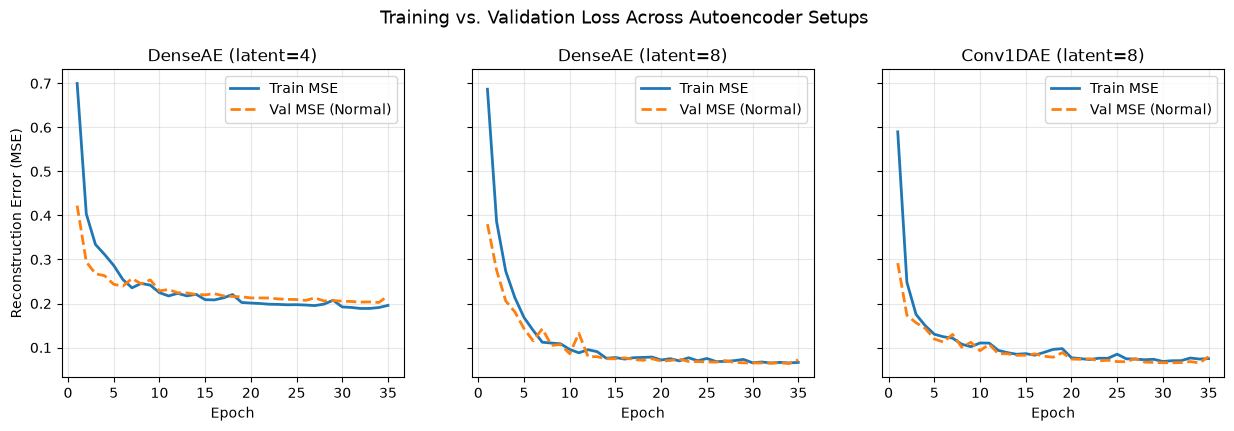

In [8]:
# Plot training & validation curves across the 3 setups
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, _) in zip(axes, SETUPS):
    h = histories[name]
    ax.plot(h["epoch"], h["train_loss"], label="Train MSE", lw=2)
    ax.plot(h["epoch"], h["val_mse"], label="Val MSE (Normal)", lw=2, linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Reconstruction Error (MSE)")
plt.suptitle("Training vs. Validation Loss Across Autoencoder Setups", fontsize=13, y=1.03)
save_fig("fig1_training_curves")
plt.show()

## 4. Anomaly Detection & Quiet Twin Similarity Search (Use Case A)

### Block 8: Reconstruction Error Histogram & ROC Curve (`fig2_anomaly_histogram_roc.png`)
This block evaluates our chosen model (`DenseAE (latent=8)`) on the held-out evaluation set `X_eval`:
- **Left panel:** Plots the distribution of reconstruction errors (MSE) for **Normal/Quiet Apartments** (blue) versus **Noisy Anomaly Apartments** (red), along with the dashed vertical decision boundary at the **95th-percentile normal validation threshold**.
- **Right panel:** Plots the Receiver Operating Characteristic (**ROC**) curve and reports the **ROC AUC** score.

Saved figure -> ..\figures\fig2_anomaly_histogram_roc.png


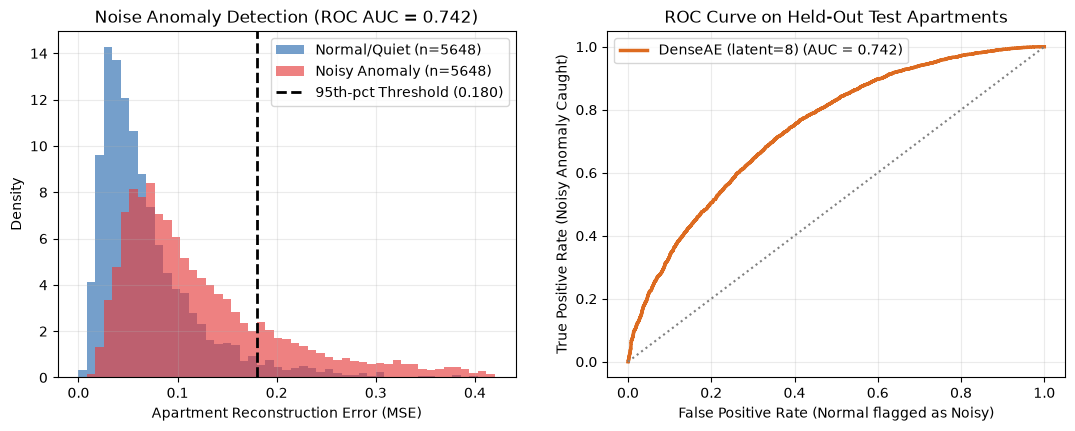

In [9]:
BEST_NAME = "DenseAE (latent=8)"
best_ae = trained_models[BEST_NAME]

val_errors = reconstruction_error(best_ae, X_val).numpy()
THRESHOLD = float(np.percentile(val_errors, 95))
eval_errors = reconstruction_error(best_ae, X_eval).numpy()
auc_score = roc_auc_score(y_eval, eval_errors)

norm_scores = eval_errors[y_eval == 0]
anom_scores = eval_errors[y_eval == 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: Anomaly error distribution
bins = np.linspace(0, np.percentile(eval_errors, 99), 50)
axes[0].hist(norm_scores, bins=bins, alpha=0.65, label=f"Normal/Quiet (n={len(norm_scores)})", color="#2b6cb0", density=True)
axes[0].hist(anom_scores, bins=bins, alpha=0.65, label=f"Noisy Anomaly (n={len(anom_scores)})", color="#e53e3e", density=True)
axes[0].axvline(THRESHOLD, color="black", linestyle="--", lw=2, label=f"95th-pct Threshold ({THRESHOLD:.3f})")
axes[0].set_xlabel("Apartment Reconstruction Error (MSE)")
axes[0].set_ylabel("Density")
axes[0].set_title(f"Noise Anomaly Detection (ROC AUC = {auc_score:.3f})")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Right: ROC Curve
fpr, tpr, _ = roc_curve(y_eval, eval_errors)
axes[1].plot(fpr, tpr, color="#dd6b20", lw=2.5, label=f"{BEST_NAME} (AUC = {auc_score:.3f})")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle=":")
axes[1].set_xlabel("False Positive Rate (Normal flagged as Noisy)")
axes[1].set_ylabel("True Positive Rate (Noisy Anomaly Caught)")
axes[1].set_title("ROC Curve on Held-Out Test Apartments")
axes[1].legend()
axes[1].grid(alpha=0.25)

save_fig("fig2_anomaly_histogram_roc")
plt.show()

### Block 9: Explainable Per-Feature Anomaly Attribution & "Quiet Twin" Similarity Search (`fig3_feature_breakdown_and_quiet_twins.png`)
When an apartment is flagged as an anomaly (`MSE > THRESHOLD`), a homebuyer wants to know **why** it failed and **which quieter apartments offer the same lifestyle**:
1. **Left Panel — Per-Feature Squared Error $(x_i - \hat{x}_i)^2$:**
   - Decomposes the total reconstruction error across all 24 features. Red bars (the 8 acoustic features) show that traffic/window noise spikes the reconstruction error, while blue bars (daylight, viewshed, layout) reconstruct normally.
2. **Right Panel & Table — Counterfactual "Quiet Twin" Latent Search:**
   - Takes the flagged noisy apartment, sets its 8 acoustic features to the normal median (`0.0` in standardized space), encodes this "ideal quiet version" into the 8D latent space $z_{\text{query}}$, and retrieves the **Top 3 nearest neighbors** by Euclidean distance among genuinely quiet apartments (`df_test_norm`).
   - As shown in the chart and table below, the Top 3 **Quiet Twins** match the query apartment's floor area, room count, solar exposure, and sky view while cutting daytime traffic noise by **15–20+ dBA**!

Saved figure -> ..\figures\fig3_feature_breakdown_and_quiet_twins.png


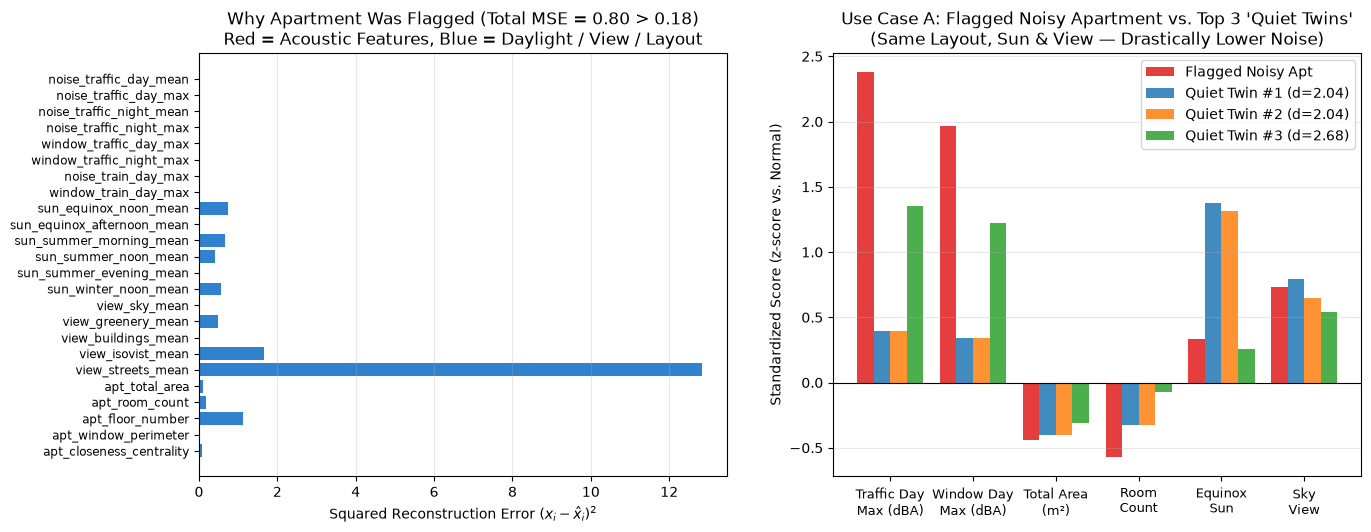

,Role,apartment_id,noise_traffic_day_max,window_traffic_day_max,apt_total_area,apt_room_count,sun_equinox_noon_mean,view_sky_mean
0,Query (Noisy Anomaly),58b437f633aeb265eceb1b675018bfab,66.076984,72.597654,68.284155,6,2.282856,0.035023
1,Quiet Twin #1,bdcc9cf6c4004b7c5324cc0772624e8d,44.992850,54.053440,70.110822,7,3.533686,0.035993
2,Quiet Twin #2,cf2b28a62f10d647b3de3915b6fea70f,45.036272,54.084582,70.110822,7,3.452546,0.033645
3,Quiet Twin #3,5eebf2f2f5ed5e7c2fde4d3cb3d9f59e,55.199282,64.139432,74.750620,8,2.191533,0.031895


In [10]:
# Per-feature reconstruction error breakdown AND Quiet Twin Similarity Search
best_ae.eval()
with torch.no_grad():
    Z_norm_test = best_ae.encode(X_test_norm.to(DEVICE)).cpu().numpy()
    rebuilt_eval = best_ae(X_eval.to(DEVICE)).cpu().numpy()

# Pick a clear noisy anomaly apartment from the test set
anom_indices = np.where(y_eval == 1)[0]
sample_anom_idx = anom_indices[np.argsort(eval_errors[anom_indices])[-10]] # A strongly anomalous apartment
x_query = X_eval_np[sample_anom_idx]
x_rebuilt = rebuilt_eval[sample_anom_idx]
per_feature_sq_err = (x_query - x_rebuilt) ** 2

# Quiet Twin Search: Counterfactual encoding!
# We take the noisy query apartment, set its 8 acoustic features to the normal median (0.0 in scaled space),
# encode into latent space, and find the 3 closest genuinely quiet apartments in df_test_norm!
x_query_quiet_target = x_query.copy()
x_query_quiet_target[:8] = 0.0  # first 8 cols are the acoustic features
with torch.no_grad():
    z_query = best_ae.encode(torch.from_numpy(x_query_quiet_target[None]).to(DEVICE)).cpu().numpy()[0]

dists = np.linalg.norm(Z_norm_test - z_query, axis=1)
top3_idx = np.argsort(dists)[:3]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Left: Per-feature error bar chart showing WHY the apartment was flagged
colors = ["#e53e3e" if i < 8 else "#3182ce" for i in range(N_FEATURES)]
y_pos = np.arange(N_FEATURES)
axes[0].barh(y_pos, per_feature_sq_err, color=colors)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(FEATURE_COLS, fontsize=8.5)
axes[0].invert_yaxis()
axes[0].set_xlabel("Squared Reconstruction Error $(x_i - \\hat{x}_i)^2$")
axes[0].set_title(f"Why Apartment Was Flagged (Total MSE = {eval_errors[sample_anom_idx]:.2f} > {THRESHOLD:.2f})\nRed = Acoustic Features, Blue = Daylight / View / Layout")
axes[0].grid(axis="x", alpha=0.3)

# Right: Quiet Twin Comparison on Non-Noise vs Noise Features (in original units)
compare_cols = [
    "noise_traffic_day_max", "window_traffic_day_max",
    "apt_total_area", "apt_room_count", "sun_equinox_noon_mean", "view_sky_mean"
]
query_raw = df_eval.iloc[sample_anom_idx][compare_cols]
twins_raw = df_test_norm.iloc[top3_idx][compare_cols]

x_locs = np.arange(len(compare_cols))
width = 0.2
# Plot normalized values (relative to query/normal scale) for visual comparison with raw numbers annotated
query_z = x_query[[FEATURE_COLS.index(c) for c in compare_cols]]
axes[1].bar(x_locs - 1.5 * width, query_z, width, label="Flagged Noisy Apt", color="#e53e3e")
for k, t_idx in enumerate(top3_idx):
    twin_z = X_test_norm_np[t_idx, [FEATURE_COLS.index(c) for c in compare_cols]]
    axes[1].bar(x_locs + (k - 0.5) * width, twin_z, width, label=f"Quiet Twin #{k+1} (d={dists[t_idx]:.2f})", alpha=0.85)

axes[1].set_xticks(x_locs)
axes[1].set_xticklabels(["Traffic Day\nMax (dBA)", "Window Day\nMax (dBA)", "Total Area\n(m²)", "Room\nCount", "Equinox\nSun", "Sky\nView"], fontsize=9)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_ylabel("Standardized Score (z-score vs. Normal)")
axes[1].set_title("Use Case A: Flagged Noisy Apartment vs. Top 3 'Quiet Twins'\n(Same Layout, Sun & View — Drastically Lower Noise)")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

save_fig("fig3_feature_breakdown_and_quiet_twins")
plt.show()

# Print raw table comparing the Noisy Query Apartment and its Top 3 Quiet Twins
summary_df = pd.concat(
    [df_eval.iloc[[sample_anom_idx]][["apartment_id"] + compare_cols].assign(Role="Query (Noisy Anomaly)"),
     df_test_norm.iloc[top3_idx][["apartment_id"] + compare_cols].assign(Role=[f"Quiet Twin #{i+1}" for i in range(3)])],
    ignore_index=True
)
summary_df[["Role", "apartment_id"] + compare_cols]

## 5. Export Model to ONNX & Verify Parity with PyTorch

### Block 10: Export `anomaly_ae.onnx`, Preprocessing Config & Example Apartments (`../model_app/`)
To prepare for Tuesday's model server (and Hugging Face upload), this block:
1. Wraps `best_ae` in `ExportableDenseAE` so the ONNX graph returns **both** `reconstruction` $(B, 24)$ and `latent` $(B, 8)$ in one call.
2. Exports `../model_app/anomaly_ae.onnx` (with dynamic batch size) and saves `../model_app/anomaly_ae.pt`.
3. Writes `../model_app/anomaly_ae_config.json` containing the exact `scaler_mean`, `scaler_scale`, `feature_names`, `threshold`, and `test_roc_auc` so the server can standardize inputs using pure NumPy without `scikit-learn`.
4. Saves 4 real example apartments (`2` quiet, `2` noisy anomalies) in `../model_app/examples/` plus a 300-apartment `quiet_twins_catalog.json` for instant similarity search on the server.

In [11]:
class ExportableDenseAE(nn.Module):
    def __init__(self, base_ae: DenseAE):
        super().__init__()
        self.encoder = base_ae.encoder
        self.decoder = base_ae.decoder

    def forward(self, features: torch.Tensor):
        latent = self.encoder(features)
        reconstruction = self.decoder(latent)
        return reconstruction, latent

export_ae = ExportableDenseAE(best_ae.cpu().eval()).eval()
torch.save(best_ae.state_dict(), MODEL_APP_DIR / "anomaly_ae.pt")

example_input = X_eval[:1]
onnx_path = MODEL_APP_DIR / "anomaly_ae.onnx"
torch.onnx.export(
    export_ae,
    (example_input,),
    onnx_path,
    input_names=["features"],
    output_names=["reconstruction", "latent"],
    dynamic_shapes={"features": {0: torch.export.Dim("batch")}},
    external_data=False,
    verbose=False,
)

config = {
    "architecture": "DenseAE",
    "latent_dim": int(best_ae.latent_dim),
    "n_features": int(N_FEATURES),
    "feature_names": FEATURE_COLS,
    "noise_feature_indices": list(range(8)),
    "scaler_mean": [round(float(x), 6) for x in scaler.mean_],
    "scaler_scale": [round(float(x), 6) for x in scaler.scale_],
    "preprocessing": "StandardScaler (x - scaler_mean) / scaler_scale fitted on normal train apartments",
    "threshold": round(THRESHOLD, 6),
    "threshold_rule": "95th percentile of reconstruction MSE on normal validation apartments",
    "test_roc_auc": round(float(auc_score), 4),
}
(MODEL_APP_DIR / "anomaly_ae_config.json").write_text(json.dumps(config, indent=2))

# Save 4 example apartments (2 quiet normal, 2 noisy anomalies) + reference catalog for Quiet Twin search
norm_example_indices = np.where(y_eval == 0)[0][:2]
anom_example_indices = [sample_anom_idx, anom_indices[np.argsort(eval_errors[anom_indices])[-5]]]

examples_meta = [
    ("quiet_apartment_1.json", int(norm_example_indices[0]), "Normal / Quiet Apartment #1"),
    ("quiet_apartment_2.json", int(norm_example_indices[1]), "Normal / Quiet Apartment #2"),
    ("noisy_apartment_1.json", int(anom_example_indices[0]), "Noisy Anomaly Apartment #1 (Street Traffic)"),
    ("noisy_apartment_2.json", int(anom_example_indices[1]), "Noisy Anomaly Apartment #2 (High Exposure)"),
]

for fname, idx, label in examples_meta:
    row = df_eval.iloc[idx]
    payload = {
        "label": label,
        "site_id": int(row["site_id"]),
        "building_id": int(row["building_id"]),
        "apartment_id": str(row["apartment_id"]),
        "features": {col: round(float(row[col]), 4) for col in FEATURE_COLS},
    }
    (MODEL_APP_DIR / "examples" / fname).write_text(json.dumps(payload, indent=2))

# Save a compact reference catalog of 300 quiet apartments with their latent vectors for Tuesday's server
ref_sub = df_test_norm.iloc[:300].reset_index(drop=True)
ref_records = []
for i in range(len(ref_sub)):
    r = ref_sub.iloc[i]
    ref_records.append({
        "apartment_id": str(r["apartment_id"]),
        "building_id": int(r["building_id"]),
        "latent": [round(float(v), 5) for v in Z_norm_test[i]],
        "features": {col: round(float(r[col]), 3) for col in FEATURE_COLS},
    })
(MODEL_APP_DIR / "quiet_twins_catalog.json").write_text(json.dumps(ref_records))

# Copy ONNX and config to ../models/ for Hugging Face upload
shutil.copy2(onnx_path, MODELS_HF_DIR / "anomaly_ae.onnx")
shutil.copy2(MODEL_APP_DIR / "anomaly_ae_config.json", MODELS_HF_DIR / "anomaly_ae_config.json")

for p in sorted(MODEL_APP_DIR.glob("*.*")) + sorted((MODEL_APP_DIR / "examples").glob("*.*")):
    print(f"{str(p):48s} {p.stat().st_size / 1024:8.1f} KB")

W1116 15:43:42.729000 476240 Lib\site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::nms
W1116 15:43:42.733000 476240 Lib\site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::roi_align
W1116 15:43:42.733000 476240 Lib\site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::roi_pool
W1116 15:43:42.733000 476240 Lib\site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::deform_conv2d


..\model_app\anomaly_ae.onnx                         47.6 KB
..\model_app\anomaly_ae.pt                           35.6 KB
..\model_app\anomaly_ae_config.json                   1.9 KB
..\model_app\onnx_verification.json                   0.2 KB
..\model_app\quiet_twins_catalog.json               270.5 KB
..\model_app\examples\noisy_apartment_1.json          1.0 KB
..\model_app\examples\noisy_apartment_2.json          1.1 KB
..\model_app\examples\quiet_apartment_1.json          1.0 KB
..\model_app\examples\quiet_apartment_2.json          1.0 KB


### Block 11: Verify Numerical Parity Between PyTorch and ONNX Runtime
Finally, we load `../model_app/anomaly_ae.onnx` with `onnxruntime.InferenceSession`, score the first 5 test apartments, and assert `np.allclose(torch_scores, onnx_scores, atol=1e-5) == True` to guarantee that Tuesday's server produces the exact same predictions as this notebook.

In [12]:
# Verify ONNX Runtime gives the exact same reconstruction error scores as PyTorch
import onnxruntime as ort

session = ort.InferenceSession(str(MODEL_APP_DIR / "anomaly_ae.onnx"))
batch = X_eval[:5].numpy()
onnx_rebuilt, onnx_latent = session.run(None, {"features": batch})
onnx_scores = ((onnx_rebuilt - batch) ** 2).mean(axis=1)
torch_scores = reconstruction_error(best_ae.to(DEVICE), X_eval[:5]).numpy()

print("PyTorch scores     :", torch_scores.round(5))
print("ONNX Runtime scores:", onnx_scores.round(5))
print("Same scores (allclose):", np.allclose(torch_scores, onnx_scores, atol=1e-5))

PyTorch scores     : [0.03119 0.07407 0.07356 0.02788 0.05492]
ONNX Runtime scores: [0.03119 0.07407 0.07356 0.02788 0.05492]
Same scores (allclose): True


### Block 12: Upload to HuggingFace

In [ ]:
# hf repos create iaac-maai/hackathon-team5-swiss-dwellings --type model --exist-ok
# hf upload iaac-maai/hackathon-team5-swiss-dwellings models . --commit-message "Upload ONNX model and model card"

# error running this, uploaded 